# Credit Card Fraud Detection: EDA, modeling and tuning

Goal: score a card transaction with the probability that it is fraud (`is_fraud`).
Fraud is rare, so the work is organized around imbalance:

- validation: stratified 5-fold CV, the same folds for every experiment
- metrics: PR-AUC (main), ROC-AUC, plus precision and recall at a chosen threshold
- decision threshold: the highest precision that still reaches a target recall

Sections: 1) EDA, 2) baselines, 3) feature engineering, 4) tuning, 5) model selection, 6) threshold.
The final model is trained by `train.py` from the configuration saved in `params/best_params.json`.

## Executive summary

- **Task:** score each card transaction with the probability of fraud. Data: 699,960 labelled transactions, 25 features, no missing values, no duplicates.
- **Key difficulty:** fraud is rare (1.67%, about 1 in 60), so accuracy is meaningless and the main metric is PR-AUC (ROC-AUC is reported as a secondary metric).
- **Result:** the selected model is a tuned **LightGBM** with PR-AUC **0.5129** and ROC-AUC **0.9472** (5-fold stratified CV, out-of-fold).
- **Operating point:** with a threshold of **0.193** the model catches **80% of frauds**, at a precision of **16%** (about 5 false alarms per caught fraud).
- **Honest caveat:** tuning improved PR-AUC by only about 0.013 over the baselines, roughly one fold standard deviation. The signal in this data is largely captured by a plain gradient boosting model.

In [1]:
import json
import os
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import ConfusionMatrixDisplay, average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.model_selection import cross_val_predict

import fraud_pipeline as fp

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid")

SEED = fp.SEED
DATA_PATH = Path(os.environ.get("DATA_PATH", "data/train.csv"))
TEST_PATH = Path(os.environ.get("TEST_PATH", "data/test.csv"))
N_TRIALS = int(os.environ.get("N_TRIALS", 40))          # Optuna trials per GBDT model
TUNE_FRAC = float(os.environ.get("TUNE_FRAC", 0.3))     # share of data used while searching
TARGET_RECALL = float(os.environ.get("TARGET_RECALL", 0.8))

Path("artifacts/oof").mkdir(parents=True, exist_ok=True)
Path("params").mkdir(exist_ok=True)

c:\Users\farhan\.conda\envs\ds\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. EDA

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"rows: {len(df):,}   columns: {df.shape[1]}   memory: {df.memory_usage(deep=True).sum() / 1e6:.0f} MB")
print(df.dtypes.astype(str).value_counts().to_dict())
df.head()

rows: 699,960   columns: 26   memory: 315 MB
{'int64': 8, 'float64': 7, 'bool': 6, 'str': 5}


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,...,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,...,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,...,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,...,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,...,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,...,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


### Missing values and duplicates

In [3]:
missing = df.isna().mean().sort_values(ascending=False)
print("Columns with missing values:")
print(missing[missing > 0].round(4).to_string() if (missing > 0).any() else "none")
dups = df.drop(columns=[fp.ID_COL], errors="ignore").duplicated().sum()
print(f"\nduplicated rows (ignoring id): {dups:,}")

Columns with missing values:
none

duplicated rows (ignoring id): 0


### Target variable

is_fraud
0.0    688271
1.0     11689

fraud rate: 1.6700%   (about 1 fraud per 60 transactions)


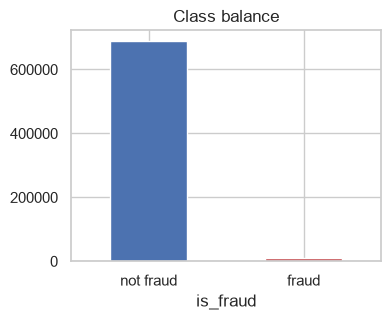

In [4]:
counts = df[fp.TARGET].value_counts().sort_index()
rate = df[fp.TARGET].mean()
print(counts.to_string())
print(f"\nfraud rate: {rate:.4%}   (about 1 fraud per {1 / rate:.0f} transactions)")
ax = counts.plot.bar(color=["#4c72b0", "#c44e52"], figsize=(4, 3))
ax.set_xticklabels(["not fraud", "fraud"], rotation=0)
ax.set_title("Class balance")
plt.show()

**Reading the target and data quality.** The dataset is clean: no missing values and no duplicated rows. Only 11,689 of 699,960 rows are fraud, so a model that always predicts "not fraud" would reach 98.3% accuracy while catching nothing. This is why every model below is compared with PR-AUC on stratified folds, which keep the same 1.67% rate in each fold.

In [5]:
X, y = fp.load_train(DATA_PATH)
num_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
cat_cols = [c for c in X.columns if c not in num_cols]
POS_WEIGHT = fp.pos_weight(y)
print(f"{len(num_cols)} numeric features, {len(cat_cols)} categorical features, negative/positive ratio {POS_WEIGHT:.1f}")

19 numeric features, 5 categorical features, negative/positive ratio 58.9


### Numeric features: ranges, distributions and outliers

In [6]:
summary = X[num_cols].describe().T
q1, q3 = X[num_cols].quantile(0.25), X[num_cols].quantile(0.75)
iqr = q3 - q1
summary["outlier_share"] = ((X[num_cols] < q1 - 1.5 * iqr) | (X[num_cols] > q3 + 1.5 * iqr)).mean()
summary.round(3)

,count,mean,std,min,25%,50%,75%,max,outlier_share
amount_usd,699960.0,79.893,205.174,1.00,15.81,27.25,43.11,6872.69,0.101
hours_since_last_txn,699960.0,6.634,6.290,0.01,2.11,4.73,9.19,51.98,0.047
txn_count_last_24h,699960.0,2.984,1.499,0.00,2.00,3.00,4.00,11.00,0.004
distance_from_home_km,699960.0,13.588,11.617,0.00,4.43,10.22,19.75,57.93,0.024
card_age_months,699960.0,46.863,5.579,25.00,43.00,47.00,51.00,73.00,0.003
customer_age,699960.0,51.430,17.899,18.00,38.00,52.00,66.00,81.00,0.000
account_balance_usd,699960.0,2064.998,3400.133,58.25,834.12,1382.74,2517.02,99701.39,0.042
cvv_retry_count,699960.0,0.085,0.290,0.00,0.00,0.00,0.00,3.00,0.083
velocity_score,699960.0,18.929,10.864,0.00,11.40,18.60,26.00,72.90,0.006
time_of_day_hour,699960.0,11.762,6.869,0.00,6.00,12.00,18.00,23.00,0.000


**Numeric features.** `amount_usd` and `account_balance_usd` are heavily right-skewed (maximum amount 6,872 against a median of 27), which explains the high outlier share. Trees are not sensitive to this, so no clipping or log transform is applied. `card_age_months` is roughly bell-shaped and the time features are close to uniform.

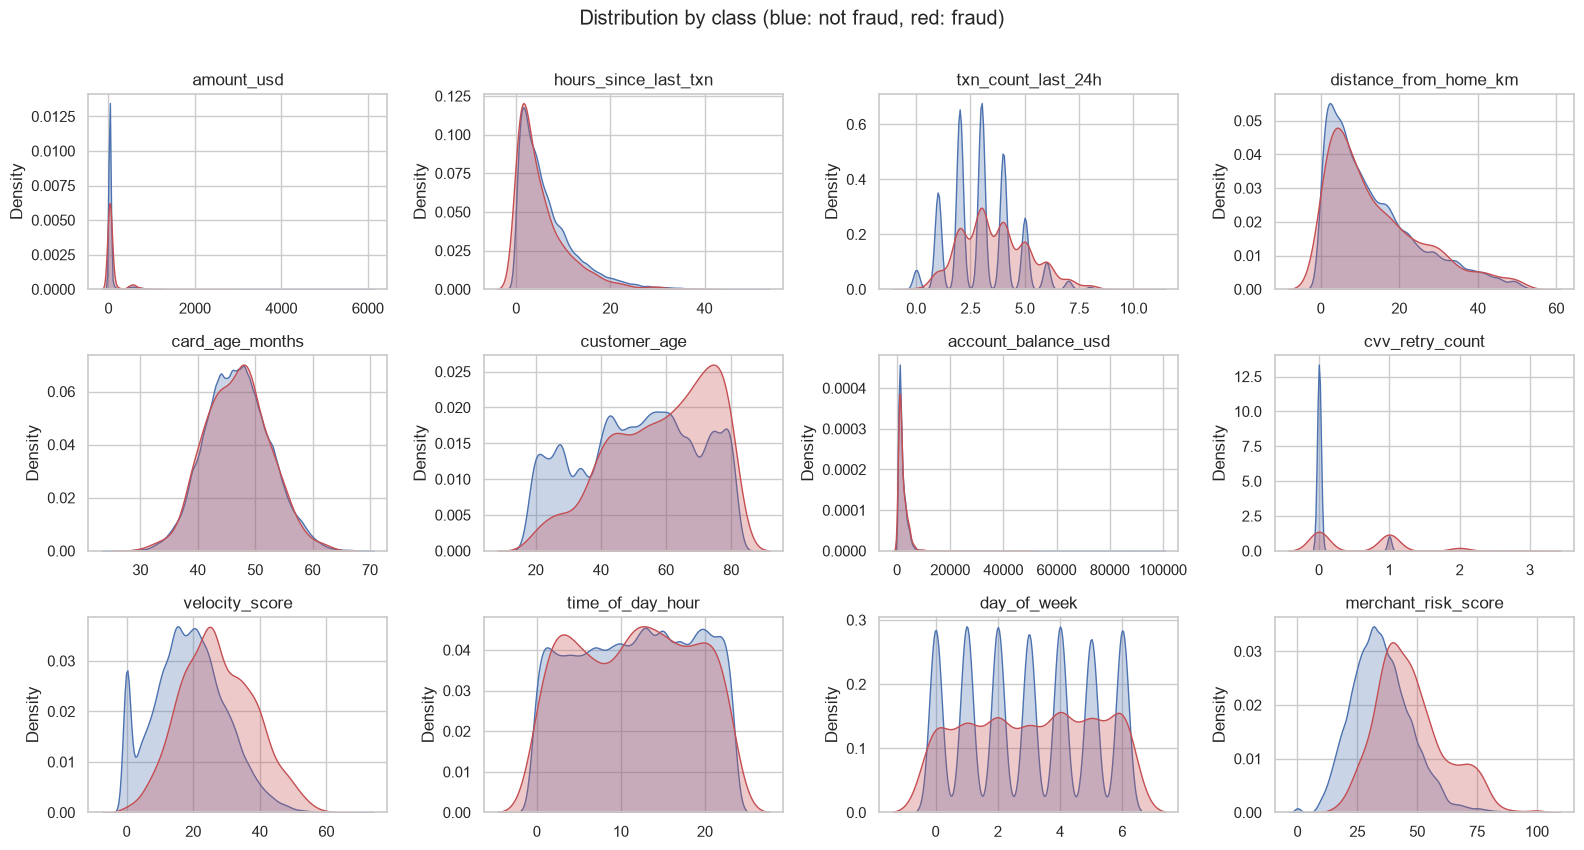

In [7]:
show = num_cols[:12]
sample = pd.concat([X[show], pd.Series(y, name=fp.TARGET)], axis=1).sample(min(len(X), 100_000), random_state=SEED)
ncols = 4
nrows = int(np.ceil(len(show) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.8 * nrows), squeeze=False)
for ax, col in zip(axes.ravel(), show):
    for label, color in [(0, "#4c72b0"), (1, "#c44e52")]:
        sns.kdeplot(sample.loc[sample[fp.TARGET] == label, col].dropna(), ax=ax, color=color,
                    fill=True, alpha=0.3, common_norm=False, warn_singular=False)
    ax.set_title(col)
    ax.set_xlabel("")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
fig.suptitle("Distribution by class (blue: not fraud, red: fraud)", y=1.01)
plt.tight_layout()
plt.show()

**Density by class (chart above).** Features that separate the classes visibly:

- `velocity_score` and `merchant_risk_score`: the fraud curve (red) is shifted to higher values.
- `cvv_retry_count`: legitimate transactions are almost all at 0, fraud has a clear share at 1 and 2 retries.
- `customer_age`: fraud skews older, with few cases among customers under 35.
- `txn_count_last_24h`: legitimate transactions form sharp peaks at integer counts, fraud is flatter and extends to higher counts.

Features with almost identical curves (`card_age_months`, `time_of_day_hour`, `hours_since_last_txn`, `distance_from_home_km`, `amount_usd`) carry little signal on their own.

### Categorical features: cardinality and fraud rate per category

card_type             5
auth_method           5
channel               5
device_type           8
merchant_category    12


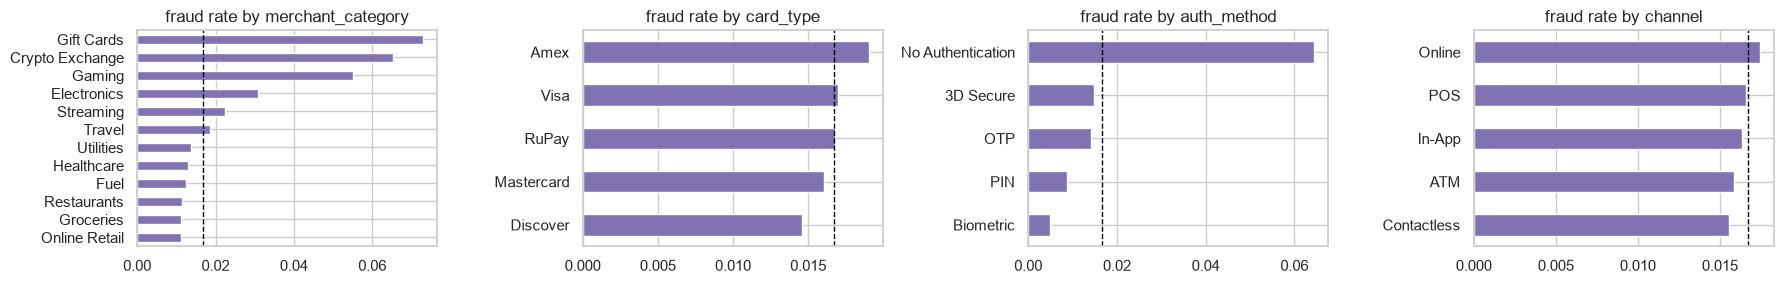

In [8]:
if cat_cols:
    print(X[cat_cols].nunique().sort_values().to_string())
    low_card = [c for c in cat_cols if X[c].nunique() <= 20][:4]
    if low_card:
        fig, axes = plt.subplots(1, len(low_card), figsize=(4.5 * len(low_card), 3), squeeze=False)
        for ax, col in zip(axes.ravel(), low_card):
            rate_by_cat = pd.Series(y).groupby(X[col].fillna("missing").to_numpy()).mean().sort_values()
            rate_by_cat.plot.barh(ax=ax, color="#8172b2")
            ax.axvline(y.mean(), color="black", ls="--", lw=1)
            ax.set_title(f"fraud rate by {col}")
        plt.tight_layout()
        plt.show()
else:
    print("no categorical features")

**Categorical features (chart above).** The dashed line is the overall fraud rate (1.67%).

- `merchant_category`: Gift Cards (about 7%), Crypto Exchange (about 6.5%) and Gaming (about 5.5%) are 3 to 4 times the average. Groceries, Online Retail and Restaurants are below 1.2%.
- `auth_method`: **No Authentication** is the strongest category signal at about 6.5%, roughly 4 times the average. Biometric is the safest at about 0.5%.
- `card_type` and `channel` barely move the fraud rate (all between 1.4% and 1.9%), so they are weak predictors.

### Correlations

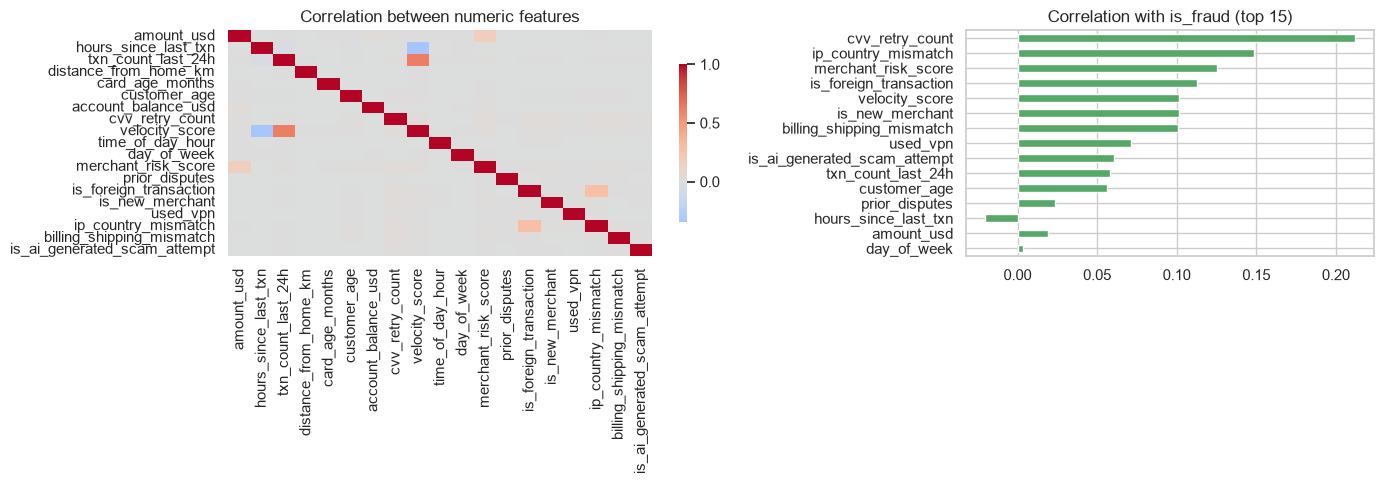

In [9]:
corr_cols = num_cols[:25]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(X[corr_cols].corr(), cmap="coolwarm", center=0, ax=axes[0], cbar_kws={"shrink": 0.7})
axes[0].set_title("Correlation between numeric features")
with_target = X[num_cols].corrwith(pd.Series(y, index=X.index)).sort_values(key=abs, ascending=False).head(15)
with_target[::-1].plot.barh(ax=axes[1], color="#55a868")
axes[1].set_title("Correlation with is_fraud (top 15)")
plt.tight_layout()
plt.show()

**Correlations.** Numeric features are almost uncorrelated with each other, so there is little multicollinearity. The only visible pairs are `velocity_score` with `txn_count_last_24h` (positive) and with `hours_since_last_txn` (negative), which is expected because a faster pace of transactions means a higher velocity.

Against the target, `cvv_retry_count` is the strongest linear signal (about 0.21), followed by `ip_country_mismatch`, `merchant_risk_score`, `is_foreign_transaction`, `velocity_score`, `is_new_merchant` and `billing_shipping_mismatch` (0.10 to 0.15). All correlations are modest, which already hints that no single feature solves the problem and a model combining many weak signals is needed.

### Feature importance

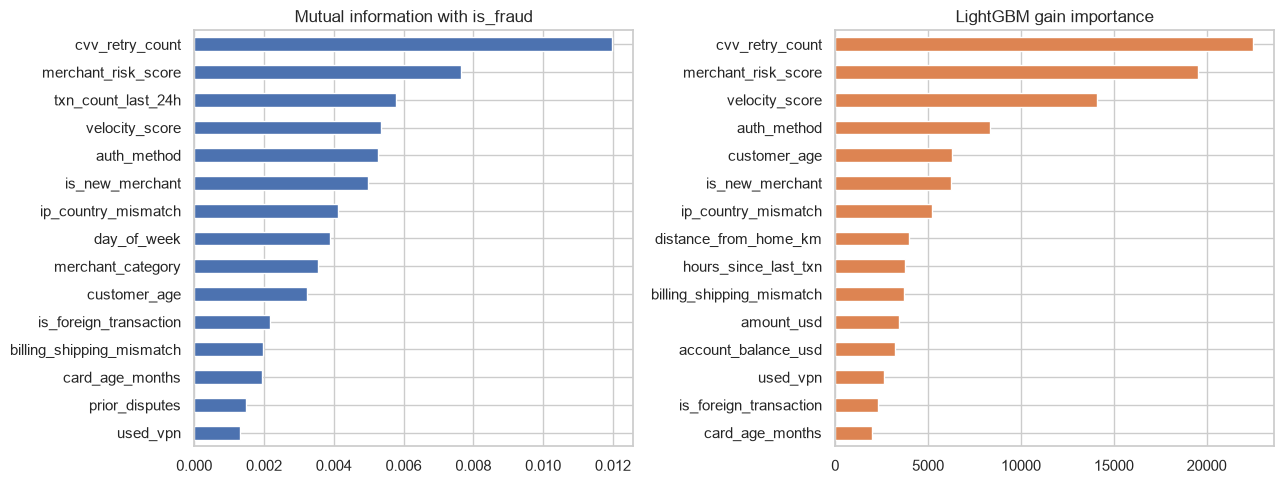

In [10]:
sample_idx = np.random.RandomState(SEED).choice(len(X), size=min(len(X), 100_000), replace=False)
Xs, ys = X.iloc[sample_idx], y[sample_idx]
pre = fp.build_preprocessor("lightgbm")
Xt = pre.fit_transform(Xs)

mi = mutual_info_classif(Xt.fillna(Xt.median()), ys, discrete_features=[c in cat_cols for c in Xt.columns], random_state=SEED)
mi = pd.Series(mi, index=Xt.columns).sort_values(ascending=False)

quick = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, importance_type="gain",
                           random_state=SEED, n_jobs=-1, verbose=-1).fit(Xt, ys)
gain = pd.Series(quick.feature_importances_, index=Xt.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mi.head(15)[::-1].plot.barh(ax=axes[0], color="#4c72b0")
axes[0].set_title("Mutual information with is_fraud")
gain.head(15)[::-1].plot.barh(ax=axes[1], color="#dd8452")
axes[1].set_title("LightGBM gain importance")
plt.tight_layout()
plt.show()

**Feature importance.** Mutual information (model-free, captures non-linear effects) and LightGBM gain importance agree on the top group: `cvv_retry_count`, `merchant_risk_score`, `velocity_score`, followed by `auth_method`, `is_new_merchant`, `ip_country_mismatch` and `customer_age`. When two independent methods give the same ranking, the signal is likely real and not an artefact of one model. Features such as `card_age_months`, `used_vpn` and `prior_disputes` contribute little, but they are kept because trees ignore useless features at low cost.

### Train vs test distribution (adversarial validation)

In [11]:
if TEST_PATH.exists():
    test = fp.coerce_types(pd.read_csv(TEST_PATH).drop(columns=[fp.ID_COL], errors="ignore"))[X.columns]
    n = min(len(X), len(test), 50_000)
    both = pd.concat([X.sample(n, random_state=SEED), test.sample(n, random_state=SEED)], ignore_index=True)
    is_test = np.r_[np.zeros(n, dtype=int), np.ones(n, dtype=int)]
    pre_adv = fp.build_preprocessor("lightgbm")
    proba = cross_val_predict(
        lgb.LGBMClassifier(n_estimators=100, random_state=SEED, n_jobs=-1, verbose=-1),
        pre_adv.fit_transform(both), is_test, cv=5, method="predict_proba")[:, 1]
    print(f"Adversarial AUC (train vs test): {roc_auc_score(is_test, proba):.3f}  (0.5 means no shift)")
else:
    print(f"{TEST_PATH} not found, skipping")

Adversarial AUC (train vs test): 0.501  (0.5 means no shift)


**Adversarial validation.** The train-vs-test AUC is 0.501, which means a classifier cannot tell the two sets apart. There is no distribution shift, so cross-validation scores should transfer to the test set.

**EDA takeaways**

- the class balance above shows how rare fraud is, so accuracy is meaningless and PR-AUC is the main metric
- ranges, missing values and outliers are summarized above; tree models handle NaN natively and logistic regression gets median imputation plus scaling
- the importance plots show which features carry signal and guide the feature engineering step

## 2. Baselines

Three model families, each with and without imbalance handling (`scale_pos_weight` for GBDTs,
`class_weight="balanced"` for logistic regression). All use the same stratified 5 folds.
GBDTs use early stopping on the validation fold, which is why `best_iter` is reported.

In [12]:
def weight_params(name, weighted):
    if not weighted:
        return {}
    return {"class_weight": "balanced"} if name == "logreg" else {"scale_pos_weight": POS_WEIGHT}


rows, OOF = [], {}
for name in fp.MODELS:
    for weighted in (False, True):
        params = weight_params(name, weighted)
        res = fp.cv_evaluate(name, X, y, params=params)
        label = name + ("_weighted" if weighted else "")
        OOF[label] = res.pop("oof")
        np.save(f"artifacts/oof/{label}.npy", OOF[label])
        rows.append({"model": label, "name": name, "params": params, "use_fe": False, **res})

baseline = pd.DataFrame(rows)
cols = ["model", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "roc_auc_std", "best_iter"]
baseline[cols].sort_values("pr_auc_mean", ascending=False).round(4)

,model,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,best_iter
4,xgboost,0.5014,0.0102,0.9455,0.0032,376.0
2,lightgbm,0.4980,0.0096,0.9453,0.0032,283.0
3,lightgbm_weighted,0.4967,0.0103,0.9446,0.0032,353.0
0,logreg,0.4895,0.0085,0.9419,0.0034,NaN
5,xgboost_weighted,0.4890,0.0115,0.9434,0.0033,241.0
1,logreg_weighted,0.4876,0.0087,0.9419,0.0033,NaN


**Baselines: reading the table.** All models land in a narrow PR-AUC band (0.488 to 0.501) with a fold std of about 0.01, so most differences between them are within noise.

- Gradient boosting (XGBoost 0.5014, LightGBM 0.4980) beats logistic regression (0.4895) by about 0.01. The linear model is already strong, which tells us the signal is mostly additive.
- **Class weighting did not help** (`*_weighted` rows are equal or lower). This is a useful finding: PR-AUC is ranking-based, so re-weighting mainly shifts probabilities and does not improve ordering. Imbalance is handled where it matters, in the decision threshold (section 6) and in stratified folds.
- Early stopping picked 283 to 376 trees for the boosted baselines.

## 3. Feature engineering

Kept small and interpretable: pairwise combinations of low-cardinality categoricals and frequency
encodings of categoricals (see `FeatureAdder` in `fraud_pipeline.py`). They are learned inside each
training fold, so nothing leaks. The rule: keep them only if PR-AUC improves by more than the
fold-to-fold standard deviation.

In [13]:
best_gbdt = (baseline[baseline.name != "logreg"].sort_values("pr_auc_mean", ascending=False).iloc[0])
with_fe = fp.cv_evaluate(best_gbdt["name"], X, y, params=best_gbdt["params"], use_fe=True)
with_fe.pop("oof")

gain = with_fe["pr_auc_mean"] - best_gbdt["pr_auc_mean"]
USE_FE = bool(gain > best_gbdt["pr_auc_std"])
print(f"{best_gbdt['model']}: PR-AUC {best_gbdt['pr_auc_mean']:.4f} -> {with_fe['pr_auc_mean']:.4f} with features "
      f"(gain {gain:+.4f}, fold std {best_gbdt['pr_auc_std']:.4f})")
print(f"ROC-AUC {best_gbdt['roc_auc_mean']:.4f} -> {with_fe['roc_auc_mean']:.4f}")
print("Decision: use engineered features" if USE_FE else "Decision: skip engineered features")

xgboost: PR-AUC 0.5014 -> 0.5013 with features (gain -0.0001, fold std 0.0102)
ROC-AUC 0.9455 -> 0.9457
Decision: skip engineered features


**Feature engineering decision.** Pairwise category combinations and frequency encoding changed PR-AUC by -0.0001, far below the fold std (0.0102). The rule was to keep new features only if the gain exceeds the std, so they are **dropped**. The raw features already contain what trees can extract.

## 4. Hyperparameter tuning

- LightGBM and XGBoost: Optuna (TPE sampler), objective is the mean PR-AUC over the same stratified 5 folds.
  The search runs on a stratified sample (`TUNE_FRAC`) for speed, then the best parameters are verified on the full data.
- Logistic regression: small grid over `C`, L1/L2 and class weight.

In [14]:
rng = np.random.RandomState(SEED)
if TUNE_FRAC < 1:
    keep = []
    for label in (0, 1):
        idx = np.where(y == label)[0]
        keep.append(rng.choice(idx, size=max(int(len(idx) * TUNE_FRAC), 1), replace=False))
    keep = np.sort(np.concatenate(keep))
    X_tune, y_tune = X.iloc[keep].reset_index(drop=True), y[keep]
else:
    X_tune, y_tune = X, y
print(f"tuning on {len(X_tune):,} rows ({y_tune.sum():,} frauds)")

SPW_CHOICES = {"none": 1.0, "sqrt": float(np.sqrt(POS_WEIGHT)), "full": POS_WEIGHT}


def lgb_params(trial):
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_samples": trial.suggest_int("min_child_samples", 10, 200),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "scale_pos_weight": SPW_CHOICES[trial.suggest_categorical("spw_mode", list(SPW_CHOICES))],
    }


def xgb_params(trial):
    return {
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 20),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "scale_pos_weight": SPW_CHOICES[trial.suggest_categorical("spw_mode", list(SPW_CHOICES))],
    }


def run_study(name, param_fn):
    def objective(trial):
        params = param_fn(trial)
        trial.set_user_attr("params", params)
        return fp.cv_evaluate(name, X_tune, y_tune, params=params, use_fe=USE_FE)["pr_auc_mean"]

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)
    return study


studies = {"lightgbm": run_study("lightgbm", lgb_params), "xgboost": run_study("xgboost", xgb_params)}
for name, study in studies.items():
    print(f"{name}: best tuning PR-AUC {study.best_value:.4f} after {len(study.trials)} trials")
    print("   ", study.best_trial.user_attrs["params"])

tuning on 209,987 rows (3,506 frauds)
lightgbm: best tuning PR-AUC 0.4949 after 40 trials
    {'learning_rate': 0.026377542826928734, 'num_leaves': 245, 'max_depth': 3, 'min_child_samples': 179, 'subsample': 0.8132023642647251, 'colsample_bytree': 0.5177159649840722, 'reg_alpha': 0.0104462854843429, 'reg_lambda': 0.41625909759111074, 'scale_pos_weight': 7.673456866741269}
xgboost: best tuning PR-AUC 0.4962 after 40 trials
    {'learning_rate': 0.02117499598050957, 'max_depth': 3, 'min_child_weight': 7, 'subsample': 0.6812055674428704, 'colsample_bytree': 0.6013995427071808, 'gamma': 4.205375371473077, 'reg_alpha': 0.04129190931148437, 'reg_lambda': 0.0066823847397837035, 'scale_pos_weight': 1.0}


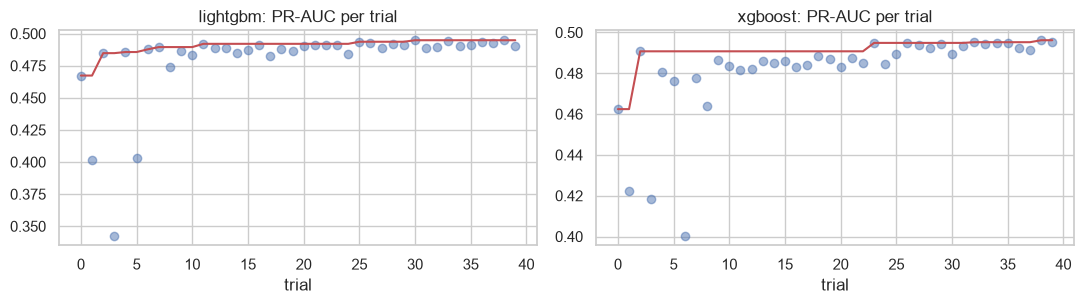

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=False)
for ax, (name, study) in zip(axes, studies.items()):
    values = [t.value for t in study.trials]
    ax.plot(values, "o", alpha=0.5)
    ax.plot(np.maximum.accumulate(values), color="#c44e52")
    ax.set_title(f"{name}: PR-AUC per trial")
    ax.set_xlabel("trial")
plt.tight_layout()
plt.show()

**Optuna history.** Both searches climb quickly: the best-so-far line (red) is flat after about 10 trials for LightGBM and about 25 for XGBoost, and later trials oscillate in a narrow band around 0.49 to 0.495. A few early trials with low scores (0.34 to 0.42) are bad regions of the space such as high learning rates. Forty trials is enough to reach the plateau, and more trials are unlikely to change the result much.

In [16]:
grid_rows = []
for C in (0.01, 0.1, 1, 10):
    for l1_ratio in (0.0, 1.0):
        for class_weight in (None, "balanced"):
            params = {"C": C, "l1_ratio": l1_ratio, "class_weight": class_weight, "max_iter": 300}
            res = fp.cv_evaluate("logreg", X_tune, y_tune, params=params, use_fe=USE_FE)
            grid_rows.append({"C": C, "penalty": "l1" if l1_ratio else "l2", "class_weight": class_weight,
                              "pr_auc": res["pr_auc_mean"], "params": params})
grid = pd.DataFrame(grid_rows).sort_values("pr_auc", ascending=False)
print(grid.drop(columns="params").head(5).round(4).to_string(index=False))

   C penalty class_weight  pr_auc
 1.0      l1          NaN  0.4855
10.0      l1          NaN  0.4855
 0.1      l1          NaN  0.4853
 0.1      l2          NaN  0.4852
 1.0      l2          NaN  0.4850


**Logistic regression grid.** All settings land between 0.485 and 0.4855, so regularisation strength and penalty type hardly matter. This is typical for a model with 25 features and 700k rows, where overfitting is not a concern.

### Verify the tuned configurations on the full data

Tuning ran on a sample, so each winner is re-evaluated on all data with the same 5 folds.

In [17]:
tuned_rows = []
tuned_configs = {
    "lightgbm_tuned": ("lightgbm", studies["lightgbm"].best_trial.user_attrs["params"]),
    "xgboost_tuned": ("xgboost", studies["xgboost"].best_trial.user_attrs["params"]),
    "logreg_tuned": ("logreg", grid.iloc[0]["params"]),
}
for label, (name, params) in tuned_configs.items():
    res = fp.cv_evaluate(name, X, y, params=params, use_fe=USE_FE)
    OOF[label] = res.pop("oof")
    np.save(f"artifacts/oof/{label}.npy", OOF[label])
    tuned_rows.append({"model": label, "name": name, "params": params, "use_fe": USE_FE, **res})

tuned = pd.DataFrame(tuned_rows)
tuned[cols].round(4)

,model,pr_auc_mean,pr_auc_std,roc_auc_mean,roc_auc_std,best_iter
0,lightgbm_tuned,0.5129,0.0116,0.9472,0.0031,1794.0
1,xgboost_tuned,0.5116,0.0104,0.9470,0.0031,1943.0
2,logreg_tuned,0.4899,0.0086,0.9419,0.0034,NaN


**Tuned models on the full data.** Tuning ran on a 30% sample, so the winners were re-evaluated on all rows. The improvement holds: LightGBM 0.4980 to **0.5129** (+0.015), XGBoost 0.5014 to 0.5116 (+0.010), logistic regression 0.4895 to 0.4899 (no change).

The best LightGBM uses very shallow trees (`max_depth` 3), a low learning rate (0.026) and strong feature subsampling (`colsample_bytree` 0.52). In other words, many small, regularised trees beat fewer deep ones. Both boosted models used 1,794 to 1,943 trees, close to the cap of 2,000, so there may be a small amount of extra gain left with a higher cap.

## 5. Model selection

In [18]:
results = pd.concat([baseline.assign(stage="baseline"), tuned.assign(stage="tuned")], ignore_index=True)
results = results.sort_values("pr_auc_mean", ascending=False).reset_index(drop=True)
display_cols = ["stage", "model", "pr_auc_mean", "pr_auc_std", "roc_auc_mean", "roc_auc_std", "best_iter"]
print(results[display_cols].round(4).to_string())

best = results.iloc[0]
print(f"\nSelected: {best['model']} (PR-AUC {best['pr_auc_mean']:.4f}, ROC-AUC {best['roc_auc_mean']:.4f})")

config = {"model": best["name"], "use_fe": bool(best["use_fe"]), "params": best["params"]}
Path("params/best_params.json").write_text(json.dumps(config, indent=2))
print(json.dumps(config, indent=2))

      stage              model  pr_auc_mean  pr_auc_std  roc_auc_mean  roc_auc_std  best_iter
0     tuned     lightgbm_tuned       0.5129      0.0116        0.9472       0.0031     1794.0
1     tuned      xgboost_tuned       0.5116      0.0104        0.9470       0.0031     1943.0
2  baseline            xgboost       0.5014      0.0102        0.9455       0.0032      376.0
3  baseline           lightgbm       0.4980      0.0096        0.9453       0.0032      283.0
4  baseline  lightgbm_weighted       0.4967      0.0103        0.9446       0.0032      353.0
5     tuned       logreg_tuned       0.4899      0.0086        0.9419       0.0034        NaN
6  baseline             logreg       0.4895      0.0085        0.9419       0.0034        NaN
7  baseline   xgboost_weighted       0.4890      0.0115        0.9434       0.0033      241.0
8  baseline    logreg_weighted       0.4876      0.0087        0.9419       0.0033        NaN

Selected: lightgbm_tuned (PR-AUC 0.5129, ROC-AUC 0.9472)
{


**Model selection.** LightGBM (0.5129) and XGBoost (0.5116) after tuning differ by 0.0013, much less than the fold std (about 0.011), so they are statistically tied. LightGBM is selected because it has the highest mean and the same ROC-AUC (0.947) as XGBoost, and it trains faster. The gain of the tuned model over the best baseline (+0.011 to +0.015) is about one std, so it is a small but consistent improvement and not a large one.

**Caveats to keep in mind:**

- Early stopping uses the same validation fold that is scored, so CV scores are slightly optimistic. This affects all boosted models equally, so the ranking is still fair.
- Tuning used 30% of the data, so the chosen parameters may not be the exact optimum for the full data.
- The out-of-fold threshold below is also estimated on the data that produced it.

## 6. Decision threshold

In fraud detection a missed fraud costs more than a false alarm, so the threshold is chosen from the
out-of-fold probabilities of the selected model as the **highest precision that still reaches the target recall**
(`TARGET_RECALL`, default 0.80). ROC-AUC is reported next to PR-AUC.

threshold 0.1929
PR-AUC 0.5127   ROC-AUC 0.9471
precision 0.161   recall 0.800   F1 0.268
confusion: TN 639,473  FP 48,798  FN 2,337  TP 9,352


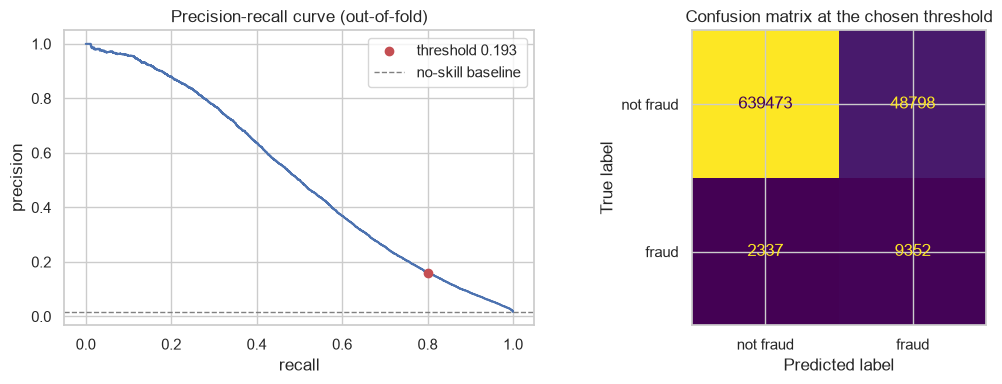

In [19]:
oof_best = OOF[best["model"]]
threshold, prec_at, rec_at = fp.pick_threshold(y, oof_best, TARGET_RECALL)
report = fp.threshold_report(y, oof_best, threshold)
print(f"threshold {threshold:.4f}")
print(f"PR-AUC {report['pr_auc']:.4f}   ROC-AUC {report['roc_auc']:.4f}")
print(f"precision {report['precision']:.3f}   recall {report['recall']:.3f}   F1 {report['f1']:.3f}")
print(f"confusion: TN {report['tn']:,}  FP {report['fp']:,}  FN {report['fn']:,}  TP {report['tp']:,}")

precision, recall, _ = precision_recall_curve(y, oof_best)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(recall, precision, color="#4c72b0")
axes[0].scatter([rec_at], [prec_at], color="#c44e52", zorder=3, label=f"threshold {threshold:.3f}")
axes[0].axhline(y.mean(), color="gray", ls="--", lw=1, label="no-skill baseline")
axes[0].set(xlabel="recall", ylabel="precision", title="Precision-recall curve (out-of-fold)")
axes[0].legend()
ConfusionMatrixDisplay.from_predictions(y, (oof_best >= threshold).astype(int), ax=axes[1],
                                        display_labels=["not fraud", "fraud"], colorbar=False, values_format="d")
axes[1].set_title("Confusion matrix at the chosen threshold")
plt.tight_layout()
plt.show()

**Threshold and business interpretation.** The PR curve shows the usual trade-off: precision falls from near 1.0 at low recall to about 0.16 at 80% recall. The curve stays well above the no-skill baseline (about 0.017), which confirms real predictive power.

At threshold **0.193**, out of 11,689 frauds the model catches **9,352** (recall 0.80) and misses 2,337. To do so it flags 48,798 legitimate transactions (about 7% of all legitimate ones), so there are roughly **5 false alarms for every caught fraud** (precision 0.161, F1 0.268).

Whether this is acceptable depends on cost. Review of a flagged transaction is cheap compared with a missed fraud, and a 5-to-1 ratio is workable for an automated step-up check (for example asking for extra authentication) but expensive for manual review. The threshold is a parameter: lowering the recall target to 0.70 would cut false alarms substantially, and the PR curve above can be used to choose the point that fits the real cost ratio.

## Next step

`python train.py` reads `params/best_params.json`, runs the 5-fold CV once more, picks the threshold,
refits on 100% of the data and saves `models/model.joblib` for the web service.

## Conclusions

1. Fraud is rare (1.67%), the data is clean and there is no train-test shift.
2. The most informative signals are `cvv_retry_count`, `merchant_risk_score`, `velocity_score`, `auth_method` (No Authentication), and high-risk merchant categories (Gift Cards, Crypto, Gaming).
3. Boosted trees outperform logistic regression slightly. Tuning gives a small gain (about +0.013 PR-AUC), feature engineering and class weighting give none.
4. Final model: tuned LightGBM, PR-AUC 0.5129, ROC-AUC 0.9472, threshold 0.193 for 80% recall (precision 0.16).

**Limitations and future work:** the metric plateau suggests the remaining error is mostly noise or hidden signal that simple features cannot reach. Ideas not yet tried: raising the tree cap, ensembling LightGBM and XGBoost (hill climbing or stacking), pseudo-labelling on the test set and seed averaging. Expected gains are small (a few thousandths of PR-AUC).